# Notebook 02 — Preparación y selección de series de precipitación diaria DHIME

**TFM:** Evaluación de la influencia del componente espacial en la estimación de datos faltantes de precipitación diaria mediante modelos de Machine Learning aplicados a estaciones meteorológicas.



---



## 1 - Objetivo del notebook


---


Este notebook toma como entrada las **(estaciones candidatas)** seleccionadas en el **"Notebook 01"** e integra los registros de precipitación diaria que deben ser desvcragados manualmente desde la plataforma DHIME del IDEAM.

El objetivo es integrar y depurar los registros, evaluar la disponibilidad  histórica de estos, verificar el solapamiento de fechas entre estaciones y la información espacial de estas, esto con el fin de seleccionar la configuración y el periodo que se utilizarán posteriormente en el experimento de imputación.

En esta etapa se conservarán los faltantes naturales de las series.

La entrada principal será:

```text
data/raw/precipitación/(archivo por estación).zip
```

y, a su vez:

```text
data/intermediate/estaciones_candidatas.geojson
```




### 1.1 - Flujo de este notebook

1. Información de entrada

2. Importación y consolidación de datos

3. Validación y depuración

4. Construcción del calendario diario

5. Evaluación de cobertura temporal

6. Análisis de solapamiento temporal

7. Incorporación de información espacial

8. Selección de estaciones candidatas

9. Comparación de configuraciones

10. Selección del periodo de estudio

11. Validación final

12. Visualización y exportación


A continuación, descargamos las librerias requeridas para el desarrollo del presente Notebook

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

tambien se hace una verificación de la estructura de archivos que maneja el proyecto, se identifica la carpeta raíz junto con la estructura de directorios utilizada por los notebooks.

In [2]:
from pathlib import Path

carpeta_actual = Path.cwd()

if carpeta_actual.name == 'notebooks':
    PROJECT_ROOT = carpeta_actual.parent
else:
    PROJECT_ROOT = carpeta_actual

folders = [
    PROJECT_ROOT / "data" / "raw"/ "precipitacion",
    PROJECT_ROOT / "data" / "intermediate",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "output" / "tables",
    PROJECT_ROOT / "output" / "figures",
    PROJECT_ROOT / "scr"
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

## 2 - Lectura del índice de estaciones candidatas


---



La descarga de los archivos de la plataforma **DHIME** se hace de manera manual dentro de la [Plataforma](https://atencionciudadano.ideam.gov.co/), para lo cual se requiere lo siguiente:



*   Variable (Tipo de estación) = Precipitación
*   Departamento
*   Municipio
*   Código de la estación (Proviene del Notebook 1)
*   Priodo = Desde el año 2000 a 2024



  En los archivos anexos del TFM se entrega la documentación oficial para la descarga de los registros.


A continuación, se define la ruta del archivo `estaciones_candidatas.geojson`, generado en el Notebook 01, siendo este la entrada espacial del Notebook 02 y contiene las estaciones candidatas junto con sus atributos y geometría.

In [3]:
# Archivo generado por el Notebook 01
ESTACIONES_CANDIDATAS_PATH =  PROJECT_ROOT / "data" / "raw" / "estaciones_candidatas.geojson"

A Continuación creamos el Geo DataFrame con la salida del Notebook 1

In [4]:
estaciones_candidatas = gpd.read_file(ESTACIONES_CANDIDATAS_PATH)
estaciones_candidatas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 35 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   CODIGO          19 non-null     object        
 1   nombre          19 non-null     object        
 2   CATEGORIA       19 non-null     object        
 3   TECNOLOGIA      19 non-null     object        
 4   ESTADO          19 non-null     object        
 5   FECHA_INST      19 non-null     datetime64[ms]
 6   altitud         19 non-null     float64       
 7   latitud         19 non-null     float64       
 8   longitud        19 non-null     float64       
 9   DEPARTAMEN      19 non-null     float64       
 10  MUNICIPIO       19 non-null     float64       
 11  AREA_OPERA      19 non-null     float64       
 12  AREA_HIDRO      19 non-null     float64       
 13  ZONA_HIDRO      19 non-null     float64       
 14  CORRIENTE       19 non-null     float64       
 15  

Para la descarga manual en la plataforma del DHIME, se necesita extraer del catálogo:

*   los nombres de las estaciones
*   localización administrativa


In [5]:
lista_estacion_CodNombre = estaciones_candidatas[["nombre","d_DEPARTAM","d_MUNICIPI"]].to_numpy().tolist() # https://docs.kanaries.net/es/topics/Pandas/dataframe-to-list
lista_estacion_CodNombre


[['UNIV PEDAGOGICA [21206190]', 'Bogotá', 'Bogota, D.C'],
 ['SOLMAFORO BOGOTA - [21205529]', 'Bogotá', 'Bogota, D.C'],
 ['BOMBEROS DEL NORTE [21205800]', 'Bogotá', 'Bogota, D.C'],
 ['JARDIN BOTANICO [21205710]', 'Bogotá', 'Bogota, D.C'],
 ['ESAP [21206040]', 'Bogotá', 'Bogota, D.C'],
 ['UNIVERSIDAD NACIONAL [21205012]', 'Bogotá', 'Bogota, D.C'],
 ['EDIFICIO PREMIUM [21206540]', 'Bogotá', 'Bogota, D.C'],
 ['SOLMAFORO BOGOTA - [21205528]', 'Bogotá', 'Bogota, D.C'],
 ["ENMANUEL D' ALZON [21201230]", 'Bogotá', 'Bogota, D.C'],
 ['OBS MET NACIONAL [21205230]', 'Bogotá', 'Bogota, D.C'],
 ['MOLINOS DEL NORTE [21206150]', 'Bogotá', 'Bogota, D.C'],
 ['VELODROMO 1 D MAYO [21205600]', 'Bogotá', 'Bogota, D.C'],
 ['ADPOSTAL [21206000]', 'Bogotá', 'Bogota, D.C'],
 ['IDEAM PUENTE ARANDA [2120500204]', 'Bogotá', 'Bogota, D.C'],
 ['LICORERA BOGOINAMA [21205820]', 'Bogotá', 'Bogota, D.C'],
 ['CENTRO MED ANDES [21205730]', 'Bogotá', 'Bogota, D.C'],
 ['SEDE IDEAM CALLE 25D KRA [21202280]', 'Bogotá', 'Bogot

La salida presenta los nombres de las estaciones candidatas y su código, junto con departamento y municipio. Esta lista es un apoyo operativo para localizar en DHIME las estaciones definidas previamente y descargar sus series de precipitación.

Una vez descargados los registros de precipitación, estos son almacenados en la carpeta de:

```text
data/raw/precipitación/(archivo por estación).zip
```


## 3 - Importación de los archivos de precipitación DHIME


---



Se define la carpeta donde se almacenaron los archivos ZIP descargados desde DHIME y se listan los archivos existentes. Esta comprobación permite verificar, antes de importarlos, qué estaciones cuentan efectivamente con archivos disponibles en la carpeta de datos crudos.

In [6]:
RUTA_PRECIPITACION = PROJECT_ROOT / "data" / "raw"/ "precipitacion"

for archivo in RUTA_PRECIPITACION.iterdir():
  if archivo.is_file():
    print(archivo.name)


21205012.zip
21206190.zip
21201600.zip
2120500204.zip
21205820.zip
21206150.zip
21202280.zip
21205730.zip
21206700.zip
21206040.zip
21205230.zip
21205600.zip
21206540.zip
21201230.zip
21205710.zip
21206000.zip


La salida muestra los nombres de los archivos ZIP encontrados. Se observa que no todas las estaciones candidatas del Notebook 01 necesariamente cuentan con registros disponibles, por lo que se debe hacer una comprobación posterior,  identificando los códigos contenidos en los archivos y no únicamente en sus nombres.

A continuación, se creará un DataFrame que contenga todo lo anteriomente importado. Para lo anterior, se define la función `cargar_archivos_precipitacion()`. La función recorre cada archivo ZIP, identifica los CSV contenidos en su interior, los lee y concatena todos los registros en un único `DataFrame`.

> ⚠️ **Advertencia**
>
> no se puede asumir que un archivo = una estación, porque  una descarga puede contener varios CodigoEstacion.


In [7]:

def cargar_archivos_precipitacion(ruta):

    from zipfile import ZipFile

    precipitacion = pd.DataFrame()

    for archivo_zip in ruta.iterdir():

        if archivo_zip.is_file() and archivo_zip.suffix.lower() == ".zip":

            with ZipFile(archivo_zip, "r") as zip_ref:

                for nombre_archivo in zip_ref.namelist():

                    if nombre_archivo.lower().endswith(".csv"):

                        with zip_ref.open(nombre_archivo) as archivo_csv:

                            df = pd.read_csv(archivo_csv)

                            precipitacion = pd.concat([precipitacion, df],ignore_index=True)

    return precipitacion


Una vez creada la función que devuelve un DataFrame de todos los archivos en formato ".zip", procedemos a llamarla para tener todo el registro historico de precipitación.

In [8]:
df_precipitacion = cargar_archivos_precipitacion(RUTA_PRECIPITACION)
df_precipitacion

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-03 00:00,mm,0.6,Definitivo
1,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-04 00:00,mm,0.1,Definitivo
2,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-05 00:00,mm,0.0,Definitivo
3,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-06 00:00,mm,1.1,Definitivo
4,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-07 00:00,mm,0.7,Definitivo
...,...,...,...,...,...,...,...,...
273744,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-12 00:00,mm,3.0,Preliminar
273745,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-13 00:00,mm,4.3,Preliminar
273746,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-14 00:00,mm,0.5,Preliminar
273747,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-15 00:00,mm,0.0,Preliminar


La salida muestra el `DataFrame` integrado con las variables `CodigoEstacion`, `NombreEstacion`, `Variable`, `Parametro`, `Fecha`, `Unidad`, `Valor` y `NivelAprobacion`. Estos registros no han sido tratados, por lo que pueden contener registros repetidos de varias estaciones.

## 4 - Validación básica de la importación


---


Una vez almacenada la información, se hace una inspección basica de esta, se consulta el tamaño del `DataFrame` importado mediante `.shape`. Esta es una comprobación básica para conocer cuántos registros y variables fueron integrados antes de iniciar la limpieza.

In [9]:
print(
    f"Información extraída de los registros de precipitación:\n"
    f"• Filas (Registros): {df_precipitacion.shape[0]:,}\n"
    f"• Columnas (Variables): {df_precipitacion.shape[1]}"
)

Información extraída de los registros de precipitación:
• Filas (Registros): 273,749
• Columnas (Variables): 8


Se importaron **273.749 registros y 8 variables**. Este número es todavía un conteo bruto, antes de la limpieza.

In [10]:
df_precipitacion.tail()

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
273744,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-12 00:00,mm,3.0,Preliminar
273745,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-13 00:00,mm,4.3,Preliminar
273746,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-14 00:00,mm,0.5,Preliminar
273747,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-15 00:00,mm,0.0,Preliminar
273748,21206000,ADPOSTAL [21206000],PRECIPITACION,Día pluviométrico (convencional),2009-06-16 00:00,mm,0.0,Preliminar


A continuación, se revisa la distribución de valores de cada columna con `value_counts()`. Esta exploración permite detectar categorías inesperadas, conocer qué estaciones aparecen en los archivos y verificar la uniformidad de variables como unidad, parámetro y tipo de observación.

In [11]:
columnas_interes = df_precipitacion.columns.to_list()

for col in columnas_interes:
    print(f"\n=== Distribución de la columna: {col} ===")
    print(df_precipitacion[col].value_counts())




=== Distribución de la columna: CodigoEstacion ===
CodigoEstacion
21205710    125472
21201230     64955
21205012     40500
21206000      8505
21206540      8459
21206040      8346
21202280      5775
21206190      5040
21201600      3628
21205730      2985
21206700        84
Name: count, dtype: int64

=== Distribución de la columna: NombreEstacion ===
NombreEstacion
JARDIN BOTANICO [21205710]             125472
ENMANUEL D' ALZON [21201230]            64955
UNIVERSIDAD NACIONAL [21205012]         40500
ADPOSTAL [21206000]                      8505
EDIFICIO PREMIUM [21206540]              8459
ESAP [21206040]                          8346
SEDE IDEAM CALLE 25D KRA [21202280]      5775
UNIV PEDAGOGICA [21206190]               5040
SEDE IDEAM KRA 10 [21201600]             3628
CENTRO MED ANDES [21205730]              2985
CEA CENT.EST.AERO. [21206700]              84
Name: count, dtype: int64

=== Distribución de la columna: Variable ===
Variable
PRECIPITACION    273749
Name: count, dtype: 

La salida confirma que los registros descargados para cada estación corresponden a la variabale **PRECIPITACION**. Otra cosa importante a resaltar es la cantidad desigual de filas por estación.

Se utiliza `.info()` para inspeccionar los tipos de datos iniciales y verificar la presencia de valores nulos dentro de las filas efectivamente importadas.

In [12]:
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273749 entries, 0 to 273748
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   CodigoEstacion   273749 non-null  int64  
 1   NombreEstacion   273749 non-null  object 
 2   Variable         273749 non-null  object 
 3   Parametro        273749 non-null  object 
 4   Fecha            273749 non-null  object 
 5   Unidad           273749 non-null  object 
 6   Valor            273749 non-null  float64
 7   NivelAprobacion  273749 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 16.7+ MB


## 5 - Estandarización de tipos


---


Según los resultados anteriores, las variables (Dtype) en su mayoría son "object", esto significa que la columna contiene texto (strings) o una mezcla de diferentes tipos de datos (como números y texto combinados). por lo que a continuación, se corrigen los tipos de variables para que los procesos posteriores no tengan algún error.

Para la estandarización, se define una lista con los tipos de datos deseados y una función que transforma cada columna según tipo. La fecha se convierte mediante `pd.to_datetime`, los valores numericon con `pd.to_numeric` y los códigos y categorías se manejan como texto.

Al final, los registros se ordenan por estación y fecha.

In [13]:
tipos_columna = [
    ['CodigoEstacion',"str"],
    ['NombreEstacion',"str"],
    ['Variable',"str"],
    ['Parametro',"str"],
    ['Unidad',"str"],
    ['Valor',"float"],
    ['NivelAprobacion',"str"],
    ["Fecha","time"]
]

def transformar_tipo_variable(listado_col,df):

    for col in listado_col:

        if col[1] == "str":
            df[col[0]] = df[col[0]].astype(col[1])

        elif col[1] == "float":
            df[col[0]] = pd.to_numeric(df[col[0]],errors="coerce")

        elif col[1] == "time":
            df[col[0]] = pd.to_datetime(df[col[0]],errors="coerce")

    df = df.sort_values(["CodigoEstacion", "Fecha"])

    return df

A continuación, se aplica la función de estandarización al conjunto completo y se vuelve a ejecutar `.info()` para comprobar que las conversiones se realizaron correctamente.

In [14]:
df_precipitacion = transformar_tipo_variable(tipos_columna,df_precipitacion)
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273749 entries, 29899 to 168653
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   CodigoEstacion   273749 non-null  object        
 1   NombreEstacion   273749 non-null  object        
 2   Variable         273749 non-null  object        
 3   Parametro        273749 non-null  object        
 4   Fecha            273749 non-null  datetime64[ns]
 5   Unidad           273749 non-null  object        
 6   Valor            273749 non-null  float64       
 7   NivelAprobacion  273749 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 18.8+ MB


Después de la transformación, `Fecha` es de tipo `datetime64[ns]`, `CodigoEstacion` se maneja como texto y `Valor` permanece numérico. Esta estructura de tipos de archivos es adecuada para realizar agrupaciones por estación y operaciones con fechas.

## 6 - Comprobación de estaciones disponibles


---



Se generan dos listas: los códigos esperados según el catálogo del Notebook 01 y los códigos que realmente pudieron ser descargados de la plataforma DHIME.

In [15]:
cod_estac_esperadas = estaciones_candidatas["CODIGO"].unique().tolist()
cod_estac_descargadas = df_precipitacion["CodigoEstacion"].unique().tolist()

Con las listas definidas (Estaciones esperadas, Estaciones descargadas) por medio de la siguiente función `descrip_info_disponible()`, para cada estación esperada, se verifica si existen registros en DHIME y, cuando existen, identifica la primera y última fecha disponible.

In [16]:
def descrip_info_disponible(esperadas,descargadas,df):

    resumen = []

    for cod_estacion in esperadas:
        resumen_estacion = {"cod_estacion": cod_estacion}

        if cod_estacion in descargadas:
            resumen_estacion["Datos_DHIME"]  = True
            resumen_estacion["fecha_inicio"] = df[df["CodigoEstacion"] == cod_estacion]["Fecha"].min()
            resumen_estacion["fecha_fin"]    = df[df["CodigoEstacion"] == cod_estacion]["Fecha"].max()
        else:
            resumen_estacion["Datos_DHIME"]  = False
            resumen_estacion["fecha_inicio"] = np.nan
            resumen_estacion["fecha_fin"]    = np.nan

        resumen.append(resumen_estacion)
        df_resumen = pd.DataFrame(resumen).sort_values(by=["Datos_DHIME","cod_estacion"],ascending=False,ignore_index=True)

    return df_resumen

Se ejecuta la función de disponibilidad comparando las estaciones esperadas con las realmente descargadas.

In [17]:
resumen_precipitacion = descrip_info_disponible(cod_estac_esperadas,cod_estac_descargadas,df_precipitacion)
resumen_precipitacion

,cod_estacion,Datos_DHIME,fecha_inicio,fecha_fin
0,21206700,True,2003-05-11,2004-02-26
1,21206540,True,2000-01-01,2003-10-13
2,21206190,True,2000-01-17,2001-11-17
3,21206040,True,2000-03-07,2008-10-01
4,21206000,True,2000-01-03,2009-06-16
5,21205730,True,2000-01-03,2009-02-08
6,21205710,True,2000-01-03,2024-12-26
7,21205012,True,2000-01-01,2024-12-29
8,21202280,True,2016-10-01,2025-01-01
9,21201600,True,2000-01-02,2019-05-01


La salida muestra que varias estaciones candidatas sí cuentan con datos DHIME y otras no, Además se didentifica que los registros de precipitación tienen rangos históricos muy diferentes: algunas cubren gran parte de 2000–2024, mientras otras terminan en los primeros años o comienzan mucho más tarde. Por ello no es posible seleccionar estaciones únicamente por proximidad espacial.

## 7 - Revisión de duplicados estación-fecha


---



Se identifican todas las filas cuya combinación `CodigoEstacion`–`Fecha` está repetida. El argumento `keep=False` marca todos los registros duplicados y no solo las repeticiones posteriores al primer registro.

In [18]:
df_precipitacion_dupli = df_precipitacion.duplicated(subset=["CodigoEstacion", "Fecha"],keep=False)
df_precipitacion_dupli.sum()

np.int64(270037)

Se detectan **270.037 filas asociadas a combinaciones estación-fecha repetidas**. El valor es muy elevado y confirma que las descargas realizadas desde DHIME contienen un fuerte solapamiento entre archivos. A continuación, se muestran unos registros marcados como duplicados, ordenándolos por estación y fecha. El objetivo es comprobar si las repeticiones corresponden realmente al mismo registro o si existen valores distintos para una misma estación y día.

In [19]:
df_precipitacion.loc[df_precipitacion_dupli].sort_values(["CodigoEstacion", "Fecha"]).head(20)

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
29899,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
52882,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
72945,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
93008,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
111856,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
134839,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
154902,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
189754,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
208602,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
239624,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo


En la salida anterior, se identifican varias apariciones de la misma estación, fecha y valor. Esto sugiere que gran parte de los duplicados procede de archivos descargados con periodos superpuestos y no de observaciones meteorológicas diferentes.

ahora se quieren ver cuántas filas están duplicadas considerando **todas las columnas**, no solo estación y fecha. Esta comparación ayuda a determinar si los registros repetidos son copias exactas.

In [20]:
df_precipitacion_total = df_precipitacion.duplicated(keep=False)
df_precipitacion_total.sum()

np.int64(270037)

El número de filas completamente duplicadas coincide con las filas previamente marcadas por estación-fecha (**270.037**), lo que indica que las repeticiones observadas son, en este conjunto, copias exactas de registros ya presentes.

A continuación, se compara el número total de filas con el número de combinaciones únicas estación-fecha. De esta manera se cuantifica cuántos registros adicionales fueron introducidos por las descargas solapadas.

In [21]:
n_total = len(df_precipitacion)

n_estacion_fecha = (
    df_precipitacion[
        ["CodigoEstacion", "Fecha"]
    ]
    .drop_duplicates()
    .shape[0]
) # Acá se almacenana los valores duplicados entre las columnas CodigoEstación y Fecha

print("Registros totales:", n_total)
print("Estación-fecha únicas:", n_estacion_fecha)
print("Registros repetidos:", n_total - n_estacion_fecha)

Registros totales: 273749
Estación-fecha únicas: 26695
Registros repetidos: 247054


De **273.749 registros brutos**, solo existen **26.695 combinaciones estación-fecha únicas**. Por diferencia se identifican **247.054 registros repetidos adicionales**. Este resultado justifica realizar una depuración antes de cualquier análisis.

Se agrupan los registros por `CodigoEstacion–Fecha` y se calcula cuántos valores distintos de precipitación existen en cada grupo. Si una combinación tuviera más de un valor diferente, se trataría de un conflicto y no de un duplicado exacto.

In [22]:
conflictos = (
    df_precipitacion
    .groupby(["CodigoEstacion", "Fecha"])["Valor"]
    .nunique()
) # En se almacenan los registros convinados de CodEstación y Fecha para evaluar si hay registros con fechas repetidas por estación pero con valor de precipitación diferente

conflictos = conflictos[conflictos > 1] # acá se verifica su hay más de un registro por fecha

conflictos

,,Valor
CodigoEstacion,Fecha,


Como resultado tenemos es una serie vacía, por lo que **no se identifican conflictos de precipitación** para una misma `CodigoEstacion–Fecha`. Esto permite eliminar los registros duplicados exactos conservando una única observación sin tener que definir reglas para resolver valores contradictorios.


Después de comprobar que no existen valores conflictivos, se eliminan las filas completamente duplicadas y se reinicia el índice.

In [23]:
df_precipitacion = (
    df_precipitacion
    .drop_duplicates()
    .reset_index(drop=True)
)

Se inspecciona nuevamente el `DataFrame` después de eliminar duplicados para verificar el tamaño final y los tipos de datos.

In [24]:
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26695 entries, 0 to 26694
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   CodigoEstacion   26695 non-null  object        
 1   NombreEstacion   26695 non-null  object        
 2   Variable         26695 non-null  object        
 3   Parametro        26695 non-null  object        
 4   Fecha            26695 non-null  datetime64[ns]
 5   Unidad           26695 non-null  object        
 6   Valor            26695 non-null  float64       
 7   NivelAprobacion  26695 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 1.6+ MB


El conjunto depurado contiene **26.695 registros**, manteniendo las 8 variables originales. La reducción respecto a las 273.749 filas iniciales confirma que la mayor parte del volumen bruto correspondía a repeticiones de las descargas y no a nuevos días observados.

Antes de dar por terminar el manejo de valores duplicados, se hace una última comprobación de duplicados por estación-fecha después de la limpieza.

In [25]:
df_precipitacion.duplicated(
    subset=["CodigoEstacion", "Fecha"],
    keep=False
).sum()

np.int64(0)

El resultado es **0**, por lo que cada combinación `CodigoEstacion–Fecha` aparece una sola vez.

## 8 - Disponibilidad temporal por estación


---



Se agrupan los datos depurados por `CodigoEstacion` y se calculan tres indicadores simples:


*   Primera fecha observada
*   Última fecha observada
*   Número de registros disponibles


In [26]:
resumen = (
    df_precipitacion.groupby("CodigoEstacion")
        .agg(
            fecha_inicio=("Fecha", "min"),
            fecha_fin=("Fecha", "max"),
            n_registros=("Fecha", "count")
        )
      .reset_index()
)

In [27]:
resumen

,CodigoEstacion,fecha_inicio,fecha_fin,n_registros
0,21201230,2000-01-03,2024-03-13,5905
1,21201600,2000-01-02,2019-05-01,3628
2,21202280,2016-10-01,2025-01-01,1925
3,21205012,2000-01-01,2024-12-29,3375
4,21205710,2000-01-03,2024-12-26,7842
5,21205730,2000-01-03,2009-02-08,995
6,21206000,2000-01-03,2009-06-16,1215
7,21206040,2000-03-07,2008-10-01,642
8,21206190,2000-01-17,2001-11-17,315
9,21206540,2000-01-01,2003-10-13,769


La disponibilidad de registros de precipitación es muy heterogénea:

* `21205710` destaca con **7.842 registros** desde 2000 hasta 2024
* `21201230` cuenta con de **5.905 registros**
* `21201600`, de **3.628 registros**
* `21205012`, de **3.375 registros**.

Varias estaciones cuentan con menores registros históricos y son mucho más cortas, lo que limita su utilidad para construir un periodo común suficientemente largo.

## 9 - Construcción del calendario diario completo


---



Se define la función que reconstruye un calendario diario continuo para cada estación. Para cada código se generan todas las fechas comprendidas entre su primera y última observación y se hace un `merge` con los registros existentes.

Cuando una fecha del calendario no tiene una observación en el archivo original, el valor queda como `NaN`. De esta forma se hacen explícitos los huecos temporales de la serie.

In [28]:
def completar_calendario_diario(df):

    # Conservar únicamente las variables necesarias (Código,Fecha y Valor Observado)
    df_base = df[["CodigoEstacion", "Fecha", "Valor"]].copy()


    # Verificar que exista una sola observación por estación y fecha - https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.any.html
    if df_base.duplicated(subset=["CodigoEstacion", "Fecha"]).any():

        raise ValueError("Existen registros duplicados para una misma estación y fecha.") # Se detiene la funcion si hay registros duplicados, esto hacer la verificación.

    listado_df = [] # Se hace un listado que almacenará cada DataFrame

    # Separar los datos por estación
    for estacion, df_estacion in df_base.groupby("CodigoEstacion"): # El elemento .Pandas.Groupby devuelve dos cosas, el código y el dataframe correspondinte dividido por estación

        fecha_inicio = df_estacion["Fecha"].min()
        fecha_final = df_estacion["Fecha"].max()

        # Crear todas las fechas esperadas
        calendario = pd.date_range(
            start=fecha_inicio,
            end=fecha_final,
            freq="D"
        )

        # Se crea un DataFrame con todos las fechas esperadas para el rango de observaciones que existe por estación
        df_calendario = pd.DataFrame({"Fecha": calendario})

        # Incorporar las observaciones existentes
        df_completo = df_calendario.merge(
            df_estacion[["Fecha", "Valor"]], # Se ponen solo dos columnas (Fecha y Valor), ya que los casos en donde no hayan coincidencias de fechas, el código lo pondrá como NAN.
            on="Fecha",
            how="left"
        )

        # Acá se asigna el código a todas las fechas,
        # incluyendo las creadas por el calendario
        df_completo["CodigoEstacion"] = estacion

        listado_df.append(df_completo)

    # Unir nuevamente todas las estaciones
    df_final = pd.concat(
        listado_df,
        ignore_index=True
    )

    # Ordenar
    df_final = df_final[
        ["CodigoEstacion", "Fecha", "Valor"]
    ].sort_values(
        ["CodigoEstacion", "Fecha"]
    ).reset_index(drop=True)

    return df_final

In [29]:
df_precipitacion_completo = completar_calendario_diario(df_precipitacion)
df_precipitacion_completo.head()

,CodigoEstacion,Fecha,Valor
0,21201230,2000-01-03,3.5
1,21201230,2000-01-04,0.0
2,21201230,2000-01-05,NaN
3,21201230,2000-01-06,0.0
4,21201230,2000-01-07,0.0


La salida muestra una serie continua de fechas.Se ve que para una fecha sin registro original aparece con `Valor = NaN`, mientras fechas con ausencia de lluvia registrada permanecen explícitamente como `0.0`. Esta diferencia será fundamental.

## 10 - Calculo de cobertura


---



Una vez se cuentan con las fechas esperadas según el intervalo de tiempo registrado por estación, se calculan días esperados dentro de su intervalo, observaciones conocidas, faltantes y porcentaje de cobertura.

In [30]:
def resumir_cobertura_estaciones(df):

    cobertura = (df.groupby("CodigoEstacion").agg(
            Fecha_inicio=("Fecha", "min"),
            Fecha_fin=("Fecha", "max"),
            Esperados=("Fecha", "count"),
            Observados=("Valor", "count")
        ).reset_index()
    )

    # Número de días sin observación
    cobertura["Faltantes"] = (cobertura["Esperados"] - cobertura["Observados"])

    # Porcentaje de datos disponibles
    cobertura["Cobertura"] = round((cobertura["Observados"] / cobertura["Esperados"]) * 100, 2)
    return cobertura

In [31]:

cobertura = resumir_cobertura_estaciones(df_precipitacion_completo)
cobertura

,CodigoEstacion,Fecha_inicio,Fecha_fin,Esperados,Observados,Faltantes,Cobertura
0,21201230,2000-01-03,2024-03-13,8837,5905,2932,66.82
1,21201600,2000-01-02,2019-05-01,7060,3628,3432,51.39
2,21202280,2016-10-01,2025-01-01,3015,1925,1090,63.85
3,21205012,2000-01-01,2024-12-29,9130,3375,5755,36.97
4,21205710,2000-01-03,2024-12-26,9125,7842,1283,85.94
5,21205730,2000-01-03,2009-02-08,3325,995,2330,29.92
6,21206000,2000-01-03,2009-06-16,3453,1215,2238,35.19
7,21206040,2000-03-07,2008-10-01,3131,642,2489,20.50
8,21206190,2000-01-17,2001-11-17,671,315,356,46.94
9,21206540,2000-01-01,2003-10-13,1382,769,613,55.64


La estación `21205710` presenta la cobertura más alta, aproximadamente **85,94 %**, seguida por `21201230` con **66,82 %** y `21201600` con **51,39 %**. Otras estaciones tienen menor cobertura o intervalos de funcionamiento más cortos.

En este punto, se puede considerar `21205710` como candidata a estación objetivo.

## 11 - Calculo de cobertura por Año


---



Se define una función de cobertura anual. Además de contar observados y faltantes por estación y año, se calcula el número real de días de cada año (365 o 366) y la disponibilidad respecto al calendario anual completo.

In [32]:
def resumir_cobertura_anual(df):

    df_anual = df.copy()

    # Extraer año
    df_anual["Anio"] = df_anual["Fecha"].dt.year

    # Resumen por estación y año
    cobertura_anual = df_anual.groupby(["CodigoEstacion", "Anio"]).agg(
            Esperados=("Fecha", "count"),
            Observados=("Valor", "count")
        ).reset_index()


    # Faltantes dentro del periodo disponible
    cobertura_anual["Faltantes"] = cobertura_anual["Esperados"] - cobertura_anual["Observados"]

    # Cobertura dentro del periodo disponible
    cobertura_anual["Cobertura"] = round((cobertura_anual["Observados"] / cobertura_anual["Esperados"])*100, 2)

    # Número real de días del año
    cobertura_anual["Dias_anio"] = (pd.to_datetime(cobertura_anual["Anio"].astype(str) + "-12-31").dt.dayofyear)

    # Disponibilidad respecto al año calendario completo
    cobertura_anual["Disponibilidad_anual"] = round(cobertura_anual["Observados"] / cobertura_anual["Dias_anio"] * 100,2)

    return cobertura_anual

In [33]:
cabertura_anio = resumir_cobertura_anual(df_precipitacion_completo)
cabertura_anio

,CodigoEstacion,Anio,Esperados,Observados,Faltantes,Cobertura,Dias_anio,Disponibilidad_anual
0,21201230,2000,364,182,182,50.00,366,49.73
1,21201230,2001,365,107,258,29.32,365,29.32
2,21201230,2002,365,136,229,37.26,365,37.26
3,21201230,2003,365,182,183,49.86,365,49.86
4,21201230,2004,366,265,101,72.40,366,72.40
...,...,...,...,...,...,...,...,...
137,21206540,2001,365,183,182,50.14,365,50.14
138,21206540,2002,365,192,173,52.60,365,52.60
139,21206540,2003,286,167,119,58.39,365,45.75
140,21206700,2003,235,71,164,30.21,365,19.45


Según la salidaanterior, se muestra que la disponibilidad de registros varía considerablemente entre años y estaciones. Esto es un problema ya que un número total de registros relativamente alto puede no ser adecuado si concentra sus datos en vez de tener una distribución uniforme de registros a lo largo del año.

A continuación, se exporta la tabla de cobertura anual a CSV como producto de control. Esto permite revisar el resultado fuera del notebook o conservarlo como evidencia del análisis exploratorio.

In [34]:
cabertura_anio.to_csv('/content/data/raw/cobertura_anual.csv', index=False)

## 12 - Selección del periodo y estaciones


---



Para la selección de la **Estación Objetivo**, así como de las estaciones que pueden ser auxiliares, se crea una función que evalua diferentes ventanas temporales que finalizan en un mismo año. Cada ventana se comprueba cuántas estaciones cumplen simultáneamente una cobertura anual mínima durante todos los años del periodo.

In [35]:
def evaluar_periodos(
    df,
    anio_fin,
    umbral_cobertura=90,
    minimo_anios=25
):

    resultados = []

    # Años que podrían utilizarse como inicio
    anios_inicio = sorted(df["Anio"].unique())

    for anio_inicio in anios_inicio:

        numero_anios = anio_fin - anio_inicio + 1

        # No evaluar periodos demasiado cortos
        if numero_anios < minimo_anios:
            continue

        # Filtrar el periodo analizado
        df_periodo = df.loc[
            (df["Anio"] >= anio_inicio) &
            (df["Anio"] <= anio_fin)
        ].copy()

        # Resumir comportamiento de cada estación
        resumen_estaciones = (
            df_periodo
            .groupby("CodigoEstacion")
            .agg(
                Anios_disponibles=("Anio", "nunique"),
                Cobertura_media=("Disponibilidad_anual", "mean"),
                Cobertura_minima=("Disponibilidad_anual", "min")
            )
            .reset_index()
        )

        # Seleccionar estaciones que cumplen el criterio
        estaciones_validas = resumen_estaciones.loc[
            (resumen_estaciones["Anios_disponibles"] == numero_anios) &
            (resumen_estaciones["Cobertura_minima"] >= umbral_cobertura)
        ]

        # Guardar resumen del periodo
        resultados.append({
            "Anio_inicio": anio_inicio,
            "Anio_fin": anio_fin,
            "Numero_anios": numero_anios,
            "Numero_estaciones": len(estaciones_validas),
            "Estaciones": estaciones_validas[
                "CodigoEstacion"
            ].tolist()
        })

    return pd.DataFrame(resultados)

Con el fin de hacer una verificación minima, se llama la función asignándole un untervalo de tiempo de 10 años y con registros que terminen en 2024, esto con el fin de verificar un rango temporal bajo y fechas más recientes. Si los resultados son favorables se puede ampliar el intervalo de fechas.

In [36]:
periodos_estaciones = evaluar_periodos(cabertura_anio, 2024, 10)
periodos_estaciones

,Anio_inicio,Anio_fin,Numero_anios,Numero_estaciones,Estaciones
0,2000,2024,25,1,[21205710]


> ⚠️ **Advertencia**
>
>El resultado muestra que, bajo un criterio mínimo de cobertura anual, solamente `21205710` cumple de forma sostenida. Por tanto, **seleccionar una única estación solo por cobertura individual es restrictivo**, ya que impediría disponer de varias estaciones para aportar información auxiliar.

> 🧭 **Decisión metodológica**
>
>La evaluación del periodo de estudio partió de la cobertura anual de las estaciones. No obstante, se comprobó que este criterio es excesivamente restrictivo para las series disponibles.
>
>Dado que el experimento de imputación exige contar con registros diarios simultáneos entre estaciones para aportar información auxiliar, la selección final se fundamenta en un análisis de solapamiento temporal diario.

## 13 - Análisis de solapamiento y selección de estaciones


---

En esta sección se evalúa la disponibilidad conjunta de las estaciones meteorológicas.

El objetivo es seleccionar:

- una **estación objetivo**;
- dos **estaciones auxiliares**;
- un **periodo de estudio** suficientemente continuo.

La selección considera tres aspectos principales:

1. cantidad de observaciones disponibles;
2. coincidencia temporal entre estaciones;
3. características espaciales, principalmente distancia y diferencia de altitud.

In [37]:
df_wide = df_precipitacion_completo.pivot(
    index="Fecha", columns="CodigoEstacion", values="Valor"
).sort_index()

df_wide.index.name = "Fecha"
print("Matriz de trabajo:", df_wide.shape)
display(df_wide.head())

Matriz de trabajo: (9133, 11)


CodigoEstacion,21201230,21201600,21202280,21205012,21205710,21205730,21206000,21206040,21206190,21206540,21206700
Fecha,,,,,,,,,,,
2000-01-01,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2000-01-02,NaN,1.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2000-01-03,3.5,12.6,NaN,37.4,0.6,5.3,1.0,NaN,NaN,2.7,NaN
2000-01-04,0.0,1.1,NaN,0.1,0.1,0.4,NaN,NaN,NaN,0.5,NaN
2000-01-05,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


### 13.1 - Disponibilidad simultánea de estaciones

Si una estación se utilizara como objetivo:

> **¿Cuántas estaciones vecinas tienen información en los mismos días en que la estación objetivo tiene un dato conocido?**

Para responder esta pregunta, los datos se transforman a una matriz donde:

- cada fila representa una fecha.
- cada columna representa una estación.
- cada celda contiene la precipitación observada o `NaN`.

In [38]:
def resumir_solapamiento(df_matriz):
    resultados = []
    estaciones = df_matriz.columns.tolist()

    for estacion in estaciones:
        vecinos = [codigo for codigo in estaciones if codigo != estacion]

        # Se analizan únicamente las fechas con precipitación conocida
        # en la estación que se está evaluando como objetivo.
        dias_objetivo = df_matriz.loc[df_matriz[estacion].notna()]
        n_vecinos = dias_objetivo[vecinos].notna().sum(axis=1)

        resultados.append({
            "CodigoEstacion": estacion,
            "Dias_objetivo_observados": len(dias_objetivo),
            "Dias_1_vecino": int((n_vecinos >= 1).sum()),
            "Dias_2_vecinos": int((n_vecinos >= 2).sum()),
            "Dias_3_vecinos": int((n_vecinos >= 3).sum())
        })

    return pd.DataFrame(resultados)


dias_solapados = resumir_solapamiento(df_wide)
display(dias_solapados.sort_values("Dias_objetivo_observados", ascending=False))

,CodigoEstacion,Dias_objetivo_observados,Dias_1_vecino,Dias_2_vecinos,Dias_3_vecinos
4,21205710,7842,6890,4823,2140
0,21201230,5905,5692,4359,2024
1,21201600,3628,3628,3314,1938
3,21205012,3375,3371,2546,1796
2,21202280,1925,1902,1563,523
6,21206000,1215,1215,1054,801
5,21205730,995,995,906,768
9,21206540,769,769,743,668
7,21206040,642,631,556,447
8,21206190,315,315,298,258


La estación `21205710` tiene **7.842 días observados**. De ellos, en **6.890** hay al menos un vecino disponible; en **4.823**, al menos dos; y en **2.140**, al menos tres. Esta combinación de observaciones propias e información vecina la convierte en una candidata relevante.

**Límite de este paso:** sabemos *cuántos* vecinos aportan información, pero no *cuáles* son ni dónde se ubican. Eso se examina a continuación.

### 13.2 - Solapamiento temporal entre pares de estaciones

A continuación, se define una función que ayuda a determinar que estación vecina coincide con cada candidata y con qué frecuencia. Se analizan todos los pares posibles, evitando comparar una estación consigo misma. Para cada par se cuentan los días en que ambas tienen precipitación observada.

In [39]:
def calcular_solapamiento_pares(df_matriz):
    resultados = []
    estaciones = df_matriz.columns.tolist()

    for objetivo in estaciones:
        observado_obj = df_matriz[objetivo].notna()
        n_dias_objetivo = int(observado_obj.sum())

        for vecina in estaciones:
            if objetivo == vecina:
                continue

            n_simultaneos = int((observado_obj & df_matriz[vecina].notna()).sum())
            porcentaje = (
                100 * n_simultaneos / n_dias_objetivo
                if n_dias_objetivo > 0 else np.nan
            )
            resultados.append({
                "Estacion_objetivo": objetivo,
                "Estacion_vecina": vecina,
                "Dias_objetivo": n_dias_objetivo,
                "Dias_simultaneos": n_simultaneos,
                "Porcentaje_solapamiento": round(porcentaje, 2)
            })

    return (
        pd.DataFrame(resultados)
        .sort_values(
            ["Estacion_objetivo", "Dias_simultaneos", "Porcentaje_solapamiento"],
            ascending=[True, False, False]
        )
        .reset_index(drop=True)
    )


df_solapamiento_pares = calcular_solapamiento_pares(df_wide)
display(df_solapamiento_pares.head(10))

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento
0,21201230,21205710,5905,4856,82.24
1,21201230,21201600,5905,3034,51.38
2,21201230,21205012,5905,1806,30.58
3,21201230,21202280,5905,1568,26.55
4,21201230,21206000,5905,751,12.72
5,21201230,21205730,5905,675,11.43
6,21201230,21206540,5905,493,8.35
7,21201230,21206040,5905,378,6.40
8,21201230,21206190,5905,157,2.66
9,21201230,21206700,5905,62,1.05


Cuando `21201230` actúa como objetivo, comparte **4.856 días** con `21205710`, equivalentes al **82,24 %** de los días observados de `21201230`. Si se invierte el par, los días simultáneos siguen siendo los mismos, pero el porcentaje cambia porque el denominador corresponde a otra estación.

Este análisis todavía no permite cerrar la selección: una vecina puede tener muchos datos coincidentes, pero encontrarse más lejos o a una altitud diferente.

### 13.3 - Incorporación de la información espacial

Además de coincidir temporalmente, se requiere identificar la distancia que las separa así como de la diferencia de altitudes.

Del catálogo del Notebook 01 se recuperan la geometría y la altitud. La información se une **dos veces** al resumen de pares: una para la estación objetivo y otra para la vecina. Así cada fila tiene las características espaciales de ambas.

La información geométrica esta proyectada en CRS = **EPSG:9377**, que maneja las unidades de medida en metros. Las distancias se presentan después en kilómetros. La diferencia de altitud se expresa en valor absoluto para representar su magnitud, sin importar cuál estación está más alta.

In [40]:
# Recuperar información espacial de las estaciones con datos.
info_geometrica_estaciones = estaciones_candidatas.loc[
    estaciones_candidatas["CODIGO"].isin(df_wide.columns),
    ["CODIGO", "altitud", "geometry"]
].copy()



# Preparar los metadatos de la estación objetivo y vecina.
metadatos_obj = pd.DataFrame(info_geometrica_estaciones).rename(
    columns={
        "CODIGO": "Estacion_objetivo",
        "altitud": "altitud_objetivo",
        "geometry": "geometry_objetivo"
    }
)

metadatos_vec = pd.DataFrame(info_geometrica_estaciones).rename(
    columns={
        "CODIGO": "Estacion_vecina",
        "altitud": "altitud_vecina",
        "geometry": "geometry_vecina"
    }
)


# Incorporar los metadatos espaciales a cada par de estaciones.
pares_con_geometria = (
    df_solapamiento_pares
    .merge(
        metadatos_obj,
        on="Estacion_objetivo",
        how="left",
        validate="many_to_one"
    )
    .merge(
        metadatos_vec,
        on="Estacion_vecina",
        how="left",
        validate="many_to_one"
    )
)


# Comprobar que no falte información espacial.
columnas_espaciales = [
    "geometry_objetivo",
    "geometry_vecina",
    "altitud_objetivo",
    "altitud_vecina"
]

if pares_con_geometria[columnas_espaciales].isna().any().any():
    raise ValueError("Existen estaciones sin geometría o altitud.")


# Convertir a GeoDataFrame.
df_solapamiento_pares_geometria = gpd.GeoDataFrame(
    pares_con_geometria,
    geometry="geometry_objetivo",
    crs=info_geometrica_estaciones.crs
)

geometria_vecina = gpd.GeoSeries(
    df_solapamiento_pares_geometria["geometry_vecina"],
    crs=info_geometrica_estaciones.crs
)


# Calcular distancia y diferencia de altitud.
df_solapamiento_pares_geometria["distancia_Km"] = (
    df_solapamiento_pares_geometria.geometry.distance(
        geometria_vecina
    ) / 1000
).round(4)

df_solapamiento_pares_geometria["diferencia_altitud_m"] = (
    df_solapamiento_pares_geometria["altitud_objetivo"]
    - df_solapamiento_pares_geometria["altitud_vecina"]
).abs()


# Construir la tabla final del análisis.
columnas_analisis = [
    "Estacion_objetivo",
    "Estacion_vecina",
    "Dias_objetivo",
    "Dias_simultaneos",
    "Porcentaje_solapamiento",
    "distancia_Km",
    "diferencia_altitud_m"
]

df_analisis_pares = (
    df_solapamiento_pares_geometria[columnas_analisis].copy()
)

display(df_analisis_pares.head(10))

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
0,21201230,21205710,5905,4856,82.24,5.0118,32.0
1,21201230,21201600,5905,3034,51.38,10.3937,165.0
2,21201230,21205012,5905,1806,30.58,7.3567,36.0
3,21201230,21202280,5905,1568,26.55,6.7777,69.0
4,21201230,21206000,5905,751,12.72,6.3278,30.0
5,21201230,21205730,5905,675,11.43,3.7257,55.0
6,21201230,21206540,5905,493,8.35,2.3740,40.0
7,21201230,21206040,5905,378,6.40,6.6648,33.0
8,21201230,21206190,5905,157,2.66,3.8294,50.0
9,21201230,21206700,5905,62,1.05,7.1957,25.0


Cada fila reúne los días y porcentaje de solapamiento de un par, su distancia horizontal y la magnitud de la diferencia altimétrica. La cercanía es un criterio que complementa la disponibilidad, **no una razón suficiente por sí sola para escoger una auxiliar**.

La altitud interviene aquí en la **caracterización y selección de estaciones**. Que se haya calculado esta variable no significa que, por sí misma, ya sea una variable predictora de un modelo de Machine Learning.

### 13.4 - Revisión de la estación objetivo y de sus auxiliares candidatas

La estación `21205710` destaca por su número de observaciones propias (apartado 13.1). Se fija como candidata a objetivo y se revisan sus vecinas.

Para no seleccionar solo por distancia, se presentan juntos el número de observaciones simultáneas, su porcentaje, la distancia y la diferencia de altitud.


In [41]:
OBJETIVO_CANDIDATO = "21205710"

revision_objetivo = (
    df_analisis_pares.loc[
        df_analisis_pares["Estacion_objetivo"] == OBJETIVO_CANDIDATO
    ]
    .sort_values("Dias_simultaneos", ascending=False)
    .reset_index(drop=True)
)

display(revision_objetivo)

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
0,21205710,21201230,7842,4856,61.92,5.0118,32.0
1,21205710,21201600,7842,3128,39.89,7.4042,133.0
2,21205710,21205012,7842,2993,38.17,3.6425,4.0
3,21205710,21202280,7842,1690,21.55,3.5770,37.0
4,21205710,21206000,7842,894,11.40,2.8827,2.0
5,21205710,21205730,7842,734,9.36,7.8668,23.0
6,21205710,21206540,7842,608,7.75,5.6024,8.0
7,21205710,21206040,7842,420,5.36,2.3875,1.0
8,21205710,21206190,7842,244,3.11,3.8131,18.0
9,21205710,21206700,7842,65,0.83,4.5004,7.0


Alrededor de `21205710`, la vecina `21201230` tiene:
* **4.856 días simultáneos** (61,92 %, 5,0118 km y 32 m de diferencia de altitud)

`21201600` presenta:
*  **3.128 días** (39,89 %, 7,4042 km y 133 m); y `21205012`, **2.993 días** (38,17 %, 3,6425 km y 4 m).

Por tanto, `21201230` es una auxiliar temporalmente relevante en ambas alternativas. Para la segunda auxiliar existe una comparación interesante: `21201600` presenta algo más de solapamiento, mientras que `21205012` es más próxima y tiene menor diferencia de altitud. **La continuidad anual decidirá cuál configuración es más útil para el experimento.**

### 13.5 - Comprobación anual del criterio de vecinos

**Pregunta:** ¿un buen total de días simultáneos significa que la información está disponible durante todo el periodo?

Un total de días simultaneos no significa que la información esté bien distribuída en el año. Una estación podría tener muchos días con vecinos, pero concentrados en pocos años. Por eso se analiza la disponibilidad año por año. Primero se compara, todavía entre **todas las estaciones vecinas posibles**, la exigencia de contar con al menos dos o al menos tres vecinos disponibles.

Este paso conserva el motivo metodológico del análisis original sin repetir tablas de cobertura y funciones ya utilizadas en el capítulo 11. **Al menos dos vecinos** no significa todavía que sean las *dos auxiliares específicas* de la configuración final; esa comprobación viene en 13.6.

In [42]:
def resumir_vecinos_por_anio(df_matriz, codigo_objetivo):

    # Limitar el análisis hasta 2024.
    matriz = df_matriz.loc[df_matriz.index.year <= 2024]

    # Identificar los días en los que la estación objetivo tiene información.
    obj_observado = matriz[codigo_objetivo].notna()

    # Contar cuántas estaciones vecinas tienen información en cada fecha.
    n_vecinos = (
        matriz.drop(columns=codigo_objetivo)
        .notna()
        .sum(axis=1)
    )

    # Crear indicadores diarios.
    base = pd.DataFrame({
        "Anio": matriz.index.year,
        "Objetivo": obj_observado,
        "Dos_vecinos": obj_observado & (n_vecinos >= 2),
        "Tres_vecinos": obj_observado & (n_vecinos >= 3)
    })

    # Contar los días disponibles de cada año.
    resumen = base.groupby("Anio").agg(
        Dias_objetivo_observados=("Objetivo", "sum"),
        Dias_2_vecinos=("Dos_vecinos", "sum"),
        Dias_3_vecinos=("Tres_vecinos", "sum")
    ).reset_index()

    # Determinar el número real de días de cada año (365 o 366).
    resumen["Dias_anio"] = pd.to_datetime(
        resumen["Anio"].astype(str) + "-12-31"
    ).dt.dayofyear

    # Calcular disponibilidad anual en porcentaje.
    resumen["Disponibilidad_2_vecinos"] = (
        resumen["Dias_2_vecinos"] / resumen["Dias_anio"] * 100
    ).round(2)

    resumen["Disponibilidad_3_vecinos"] = (
        resumen["Dias_3_vecinos"] / resumen["Dias_anio"] * 100
    ).round(2)

    return resumen

In [43]:
df_revision_anual_objetivo = resumir_vecinos_por_anio(df_wide, OBJETIVO_CANDIDATO)
display(df_revision_anual_objetivo.loc[
    df_revision_anual_objetivo["Anio"].between(2004, 2015)
])

,Anio,Dias_objetivo_observados,Dias_2_vecinos,Dias_3_vecinos,Dias_anio,Disponibilidad_2_vecinos,Disponibilidad_3_vecinos
4,2004,221,172,93,366,46.99,25.41
5,2005,284,207,127,365,56.71,34.79
6,2006,298,179,51,365,49.04,13.97
7,2007,174,91,28,365,24.93,7.67
8,2008,301,210,124,366,57.38,33.88
9,2009,355,168,26,365,46.03,7.12
10,2010,334,188,0,365,51.51,0.00
11,2011,339,256,189,365,70.14,51.78
12,2012,335,192,89,366,52.46,24.32
13,2013,334,203,146,365,55.62,40.00


Para la estación `21205710`, disponer de **al menos tres vecinos** reduce considerablemente los días utilizables. Al exigir **al menos dos**, aumenta la cobertura y se conserva información a lo largo del intervalo 2004-2015.

### 13.6 - Comparación de dos configuraciones concretas

Se comparan dos alternativas, ambas formadas por **tres estaciones en total**:

- **Configuración A:** objetivo `21205710` y auxiliares `21201230` y `21201600`.

- **Configuración B:** objetivo `21205710` y auxiliares `21201230` y `21205012`.

Ahora el criterio es más exigente y específico: un día cuenta como **simultáneo** únicamente si **las tres estaciones de esa configuración** tienen datos conocidos. La función calcula ese conteo para cada año y lo divide por los 365 o 366 días correspondientes.

In [44]:
def resumir_disponibilidad_configuracion(df_matriz, estaciones, nombre_configuracion):
    # La misma selección de fechas para todas las alternativas (hasta 2024).
    matriz = df_matriz.loc[df_matriz.index.year <= 2024]
    if len(estaciones) != len(set(estaciones)):
        raise ValueError("La configuración contiene códigos de estación repetidos.")

    # True solamente cuando todas las estaciones de la configuración tienen dato.
    dias_simultaneos = matriz[estaciones].notna().all(axis=1)
    tabla = pd.DataFrame({
        "Anio": matriz.index.year,
        "Disponible": dias_simultaneos.astype(int)
    }, index=matriz.index)

    resumen = (
        tabla.groupby("Anio", as_index=False)
        .agg(Dias_simultaneos=("Disponible", "sum"))
    )
    resumen["Dias_anio"] = pd.to_datetime(
        resumen["Anio"].astype(str) + "-12-31"
    ).dt.dayofyear
    resumen["Disponibilidad_pct"] = (
        resumen["Dias_simultaneos"] / resumen["Dias_anio"] * 100
    ).round(2)
    resumen["Configuracion"] = nombre_configuracion
    return resumen


config_A = ["21205710", "21201230", "21201600"]
config_B = ["21205710", "21201230", "21205012"]

resumen_A = resumir_disponibilidad_configuracion(df_wide, config_A, "A")
resumen_B = resumir_disponibilidad_configuracion(df_wide, config_B, "B")

comparacion_configuraciones = pd.concat([resumen_A, resumen_B], ignore_index=True)
comparacion_periodos = comparacion_configuraciones.pivot(
    index="Anio", columns="Configuracion", values="Disponibilidad_pct"
)
display(comparacion_periodos)

Configuracion,A,B
Anio,,
2000,28.14,35.25
2001,18.90,22.47
2002,30.96,34.52
2003,27.12,26.58
2004,33.06,13.66
2005,37.26,23.01
2006,38.90,0.00
2007,19.18,0.00
2008,38.80,0.00


En el periodo 2004-2015, la configuración B registra **0 % de disponibilidad conjunta** en 2006-2010 y 2014-2015. En cambio, A conserva días simultáneos en todos esos años. Aunque B incorpora una estación más cercana y con menor diferencia altitudinal, su interrupción temporal dificulta construir un experimento continuo.

**Decisión:** se adopta la **configuración A** para continuar con la selección del periodo. No se trata de afirmar que A sea la mejor combinación posible bajo todos los criterios, sino que resulta más adecuada que B para el diseño experimental planteado.

### 13.7 - Selección del periodo de estudio

Para determinar dentro de la configuración seleccionada, el intervalo que puede utilizarse para el experimento se revisan los días simultáneos de **A** año por año. Se selecciona **2004-2015**, un bloque de **12 años consecutivos** con información conjunta en todos los años. Los primeros años también contienen algunas coincidencias, pero se adopta esta ventana de trabajo por su continuidad y por su utilidad para dividir después la serie en entrenamiento, validación y prueba.

Esta elección es una **decisión metodológica**; no se presenta como una optimización exhaustiva de todos los intervalos posibles.

In [45]:
PERIODO_INICIO = "2004-01-01"
PERIODO_FIN = "2015-12-31"

periodo_candidato = resumen_A.loc[
    resumen_A["Anio"].between(2004, 2015),
    ["Anio", "Dias_simultaneos", "Dias_anio", "Disponibilidad_pct", "Configuracion"]
].copy()

print("Años del periodo:", len(periodo_candidato))
print("Días con las tres estaciones completas:", int(periodo_candidato["Dias_simultaneos"].sum()))
display(periodo_candidato)

Años del periodo: 12
Días con las tres estaciones completas: 1789


,Anio,Dias_simultaneos,Dias_anio,Disponibilidad_pct,Configuracion
4,2004,121,366,33.06,A
5,2005,136,365,37.26,A
6,2006,142,365,38.90,A
7,2007,70,365,19.18,A
8,2008,142,366,38.80,A
9,2009,154,365,42.19,A
10,2010,188,365,51.51,A
11,2011,189,365,51.78,A
12,2012,165,366,45.08,A
13,2013,151,365,41.37,A


Para el periodo entre 2004-2015, la disponibilidad conjunta anual de **A** se sitúa aproximadamente entre **19 % y 52 %**, y la suma del periodo es de **1.789 días con las tres estaciones completas**

### 13.8 - Validación de la selección final

Se extraen las tres estaciones de la configuración A para todo el calendario 2004-2015. Después se identifican únicamente las fechas en que las tres contienen observación. El conteo directo debe coincidir con la suma anual calculada anteriormente.

In [46]:
ESTACION_OBJETIVO = config_A[0]
ESTACIONES_AUXILIARES = config_A[1:]
ESTACIONES_SELECCIONADAS = [ESTACION_OBJETIVO, *ESTACIONES_AUXILIARES]
FECHA_INICIO = PERIODO_INICIO
FECHA_FIN = PERIODO_FIN

# Se conserva toda la serie diaria y sus NaN naturales.
df_periodo = df_wide.loc[FECHA_INICIO:FECHA_FIN, ESTACIONES_SELECCIONADAS].copy()
df_periodo.index.name = "Fecha"

# Esta segunda tabla es solo una comprobación; NO sustituye a df_periodo.
dias_completos = df_periodo.notna().all(axis=1)
df_periodo_completo = df_periodo.loc[dias_completos].copy()

n_directo = len(df_periodo_completo)
n_anual = int(periodo_candidato["Dias_simultaneos"].sum())
print("Días simultáneos (conteo directo):", n_directo)
print("Días simultáneos (suma anual):", n_anual)
print("Valores nulos en el subconjunto completo:")
print(df_periodo_completo.isna().sum())

assert n_directo == n_anual, "El conteo directo no coincide con el resumen anual."
assert not df_periodo_completo.isna().any().any(), "Hay NaN en el subconjunto completo."
assert df_periodo.index.is_unique, "Hay fechas duplicadas en el periodo seleccionado."

Días simultáneos (conteo directo): 1789
Días simultáneos (suma anual): 1789
Valores nulos en el subconjunto completo:
CodigoEstacion
21205710    0
21201230    0
21201600    0
dtype: int64


## 14 - Visualización y guardado de las salidas

La estación objetivo es (`21205710`), las dos auxiliares (`21201230` y `21201600`) y el intervalo de años es (`2004-01-01` a `2015-12-31`). A continuación se prepara la salida espacial, se representa su ubicación y se exportan los tres archivos que leerá el Notebook 03.



### 14.1 - Preparación de las estaciones seleccionadas

Se recuperan del catálogo original las tres estaciones con **todos sus atributos**, incluida la geometría. Se agrega la columna booleana `Objetivo`: `True` para la estación objetivo y `False` para las dos auxiliares. El Notebook 03 utiliza esta columna para identificar automáticamente cada rol.

In [47]:
# Se conserva el orden objetivo, auxiliar 1 y auxiliar 2.
estaciones_seleccionadas_gdf = (
    estaciones_candidatas.loc[
        estaciones_candidatas["CODIGO"].isin(ESTACIONES_SELECCIONADAS)
    ]
    .set_index("CODIGO")
    .loc[ESTACIONES_SELECCIONADAS]
    .reset_index()
    .copy()
)
estaciones_seleccionadas_gdf = gpd.GeoDataFrame(
    estaciones_seleccionadas_gdf,
    geometry="geometry",
    crs=estaciones_candidatas.crs
)
estaciones_seleccionadas_gdf["Objetivo"] = (
    estaciones_seleccionadas_gdf["CODIGO"] == ESTACION_OBJETIVO
)

assert len(estaciones_seleccionadas_gdf) == 3
assert estaciones_seleccionadas_gdf["Objetivo"].sum() == 1
assert estaciones_seleccionadas_gdf.crs.to_epsg() == 9377

display(estaciones_seleccionadas_gdf[["CODIGO", "nombre", "altitud", "Objetivo", "geometry"]])

,CODIGO,nombre,altitud,Objetivo,geometry
0,21205710,JARDIN BOTANICO [21205710],2552.0,True,POINT (4877927.545 2073889.531)
1,21201230,ENMANUEL D' ALZON [21201230],2520.0,False,POINT (4881340.437 2077559.696)
2,21201600,SEDE IDEAM KRA 10 [21201600],2685.0,False,POINT (4881038.215 2067170.438)


### 14.2 - Mapa de la configuración seleccionada

Se representan la estación objetivo y las auxiliares con símbolos diferentes. El mapa permite verificar visualmente su distribución. El fondo cartográfico se intenta cargar con `contextily`.

In [50]:
!pip install contextily

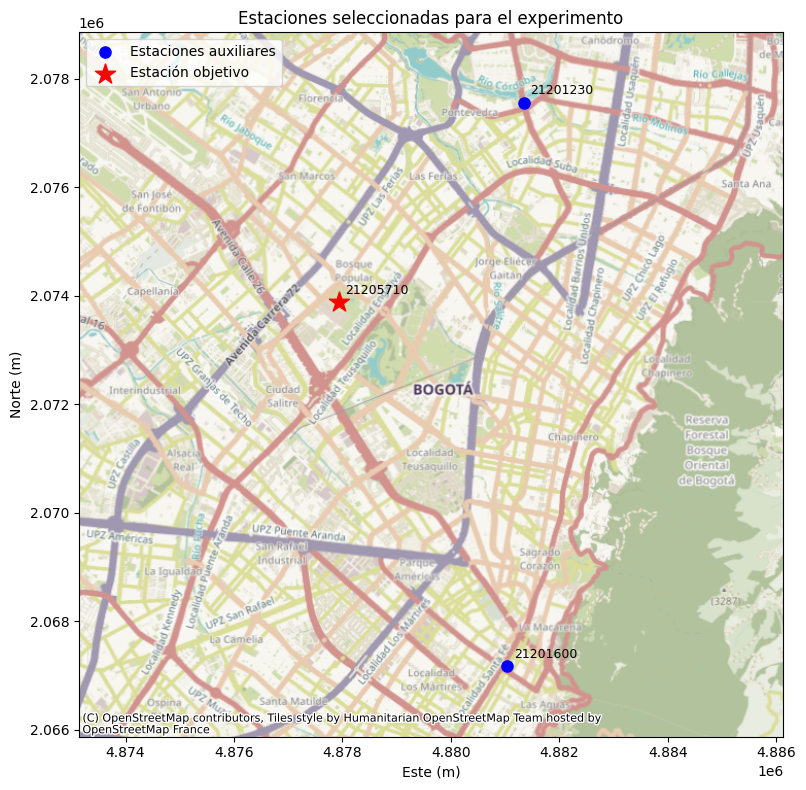

In [51]:
fig, ax = plt.subplots(figsize=(10, 8))

aux_plot = estaciones_seleccionadas_gdf.loc[
    ~estaciones_seleccionadas_gdf["Objetivo"]
]
obj_plot = estaciones_seleccionadas_gdf.loc[
    estaciones_seleccionadas_gdf["Objetivo"]
]

aux_plot.plot(ax=ax, marker="o", color="blue", markersize=65,
              label="Estaciones auxiliares", zorder=2)
obj_plot.plot(ax=ax, marker="*", color="red", markersize=230,
              label="Estación objetivo", zorder=3)

for _, fila in estaciones_seleccionadas_gdf.iterrows():
    ax.annotate(fila["CODIGO"], (fila.geometry.x, fila.geometry.y),
                xytext=(5, 6), textcoords="offset points", fontsize=9)

xmin, ymin, xmax, ymax = estaciones_seleccionadas_gdf.total_bounds
lado = max(xmax - xmin, ymax - ymin)
centro_x, centro_y = (xmin + xmax) / 2, (ymin + ymax) / 2
margen = 1.25
ax.set_xlim(centro_x - lado * margen / 2, centro_x + lado * margen / 2)
ax.set_ylim(centro_y - lado * margen / 2, centro_y + lado * margen / 2)

try:
    import contextily as cx
    cx.add_basemap(ax, crs=estaciones_seleccionadas_gdf.crs,
                   source=cx.providers.OpenStreetMap.HOT)
except (ImportError, OSError, ConnectionError, ValueError) as exc:
    print("No se pudo cargar el mapa base; se conserva el mapa de estaciones:", exc)

ax.set_title("Estaciones seleccionadas para el experimento")
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
ax.legend()
plt.tight_layout()

RUTA_FIGURAS = PROJECT_ROOT / "output" / "figures"
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
fig.savefig(RUTA_FIGURAS / "02_estaciones_seleccionadas.png", dpi=180, bbox_inches="tight")
plt.show()

### 14.3 - Guardado de los archivos para el Notebook 03

Se exportan tres productos, cada uno con una función diferente:

1. **`disponibilidad_periodo_seleccionado.parquet`**: resumen anual del periodo 2004-2015 de la configuración A (conteos y porcentaje de días con las tres estaciones observadas).
2. **`precipitacion_periodo_seleccionado.parquet`**: serie diaria completa del mismo periodo, con las tres estaciones como columnas **y con los faltantes naturales sin modificar**.
3. **`estaciones_seleccionadas.geojson`**: información geográfica y atributos de las tres estaciones, incluida la columna `Objetivo`.

Estos nombres y contenidos coinciden con las entradas declaradas en el Notebook 03. Los archivos se guardan en `data/intermediate`, porque son datos preparados a partir de los registros originales, no nuevas descargas brutas.

In [53]:
RUTA_INTERMEDIATE = PROJECT_ROOT / "data" / "intermediate"
RUTA_INTERMEDIATE.mkdir(parents=True, exist_ok=True)

RESUMEN_PATH = RUTA_INTERMEDIATE / "disponibilidad_periodo_seleccionado.parquet"
PERIODO_SELECCIONADO_PATH = RUTA_INTERMEDIATE / "precipitacion_periodo_seleccionado.parquet"
ESTACIONES_SELECCIONADAS_PATH = RUTA_INTERMEDIATE / "estaciones_seleccionadas.geojson"

# Importante: guardar df_periodo y NO df_periodo_completo.
periodo_candidato.to_parquet(RESUMEN_PATH, index=True)
df_periodo.to_parquet(PERIODO_SELECCIONADO_PATH, index=True)
estaciones_seleccionadas_gdf.to_file(ESTACIONES_SELECCIONADAS_PATH, driver="GeoJSON")

print("Archivos exportados:")
print(RESUMEN_PATH)
print(PERIODO_SELECCIONADO_PATH)
print(ESTACIONES_SELECCIONADAS_PATH)

Archivos exportados:
/content/data/intermediate/disponibilidad_periodo_seleccionado.parquet
/content/data/intermediate/precipitacion_periodo_seleccionado.parquet
/content/data/intermediate/estaciones_seleccionadas.geojson


### Cierre del Notebook 02

Se seleccionó la estación **21205710** como objetivo, con las estaciones **21201230** y **21201600** como auxiliares, para el periodo **2004-2015**. La configuración A conserva **1.789 días con observaciones simultáneas de las tres estaciones** dentro de ese intervalo.

